# Synthetic data


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import copy

import os
%config InlineBackend.figure_format ='retina'

%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *

from RealTrace_paper_analysis.plotting_src.naive_rates import *

from mpl_toolkits.axes_grid1.inset_locator import (inset_axes, InsetPosition,
                                                  mark_inset)
import matplotlib
%config InlineBackend.figure_format ='retina'


header_setting.py: using old naming


## Predictions simulated data


In [2]:
# get files


directory = '../../data_realtrace_paper/glucose_hi1_simulation1000_adder_wo_bleaching/glucose_hi1_simulation1000_adder_wo_bleaching_0/'
sample = directory.split("/")[-2]

paramter_settings = {'mean_lambda': 'free',
                    'gamma_lambda': 'free',
                    'var_lambda': 'free',
                    'mean_q': 'free',
                    'gamma_q': 'free',
                    'var_q':'free',
                    'beta':'fixed',
                    'var_x':'free',
                    'var_g':'free',
                    'var_dx':'free',
                    'var_dg':'free'} 


paramter_settings_list = [paramter_settings]
filebase = default_filebase(directory, sample) # default

dat_file = directory + sample + ".csv"
prediction_file_f, prediction_file_b, prediction_file = get_prediction_files(filebase, paramter_settings_list)
iter_file, final_file = get_minimization_file(filebase, paramter_settings)

indata = pd.read_csv(dat_file, dtype={"parent_id":str, "cell_id":str})
prediction = pd.read_csv(prediction_file, skiprows=header_lines(prediction_file), 
                         dtype={"parent_id":str, "cell_id":str})
# indata["cell_id"] = indata["lane"].astype(str) + '.' + indata["cell_id"].astype(str)
# indata["parent_id"] = indata["lane"].astype(str) + '.' + indata["parent_id"].astype(str)

cells_true = df2cells(indata, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")

cells_prediction = ggp_df2cells(prediction, time="time", log_length="mean_x", gfp="mean_g", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="mean_l", qt="mean_q")

cells_noise = df2cells(indata, time="time_min", log_length="log_length_noise", gfp="gfp_noise", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")


full_data = pd.read_csv(directory + sample + "_full.csv", 
                       dtype={"parent_id":str, "cell_id":str})

cells_full = df2cells(full_data, time="time_min", log_length="log_length", gfp="gfp", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="lt", qt="qt")



In [3]:
# read samples as list of celllists
samples = []
samples_file = '../../data_realtrace_paper/glucose_hi1_simulation1000_adder_wo_bleaching/glucose_hi1_simulation1000_adder_wo_bleaching_0/glucose_hi1_simulation1000_adder_wo_bleaching_0_out/glucose_hi1_simulation1000_adder_wo_bleaching_0_f_b_samples.csv'

samples_dat = pd.read_csv(samples_file, skiprows=header_lines(samples_file), 
                         dtype={"parent_id":str, "cell_id":str})
for i in range(10):
    sample_temp = samples_dat[samples_dat["sample"]==i]
    cells_temp = df2cells(sample_temp, time="time", log_length="x", gfp="g", 
                            cell_id="cell_id", parent_id="parent_id", 
                            lt="l", qt="q")
    samples.append(cells_temp)
    
    

In [4]:

def get_path_idx(cells, idx0=0):
    idx = []
    last_cell = cells[idx0].parent_id
    for i, _ in enumerate(cells):
        if last_cell == cells[i].parent_id: 
            last_cell = cells[i].cell_id
            idx.append(i)
    return idx

def gaussian(x, y):
    mean = np.mean(y)
    sigma = np.std(y)
    return 1./(np.sqrt(2*np.pi)*sigma) * np.exp(-(x-mean)**2/(2*sigma**2))


def gauss_function(x, a, x0, sigma):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


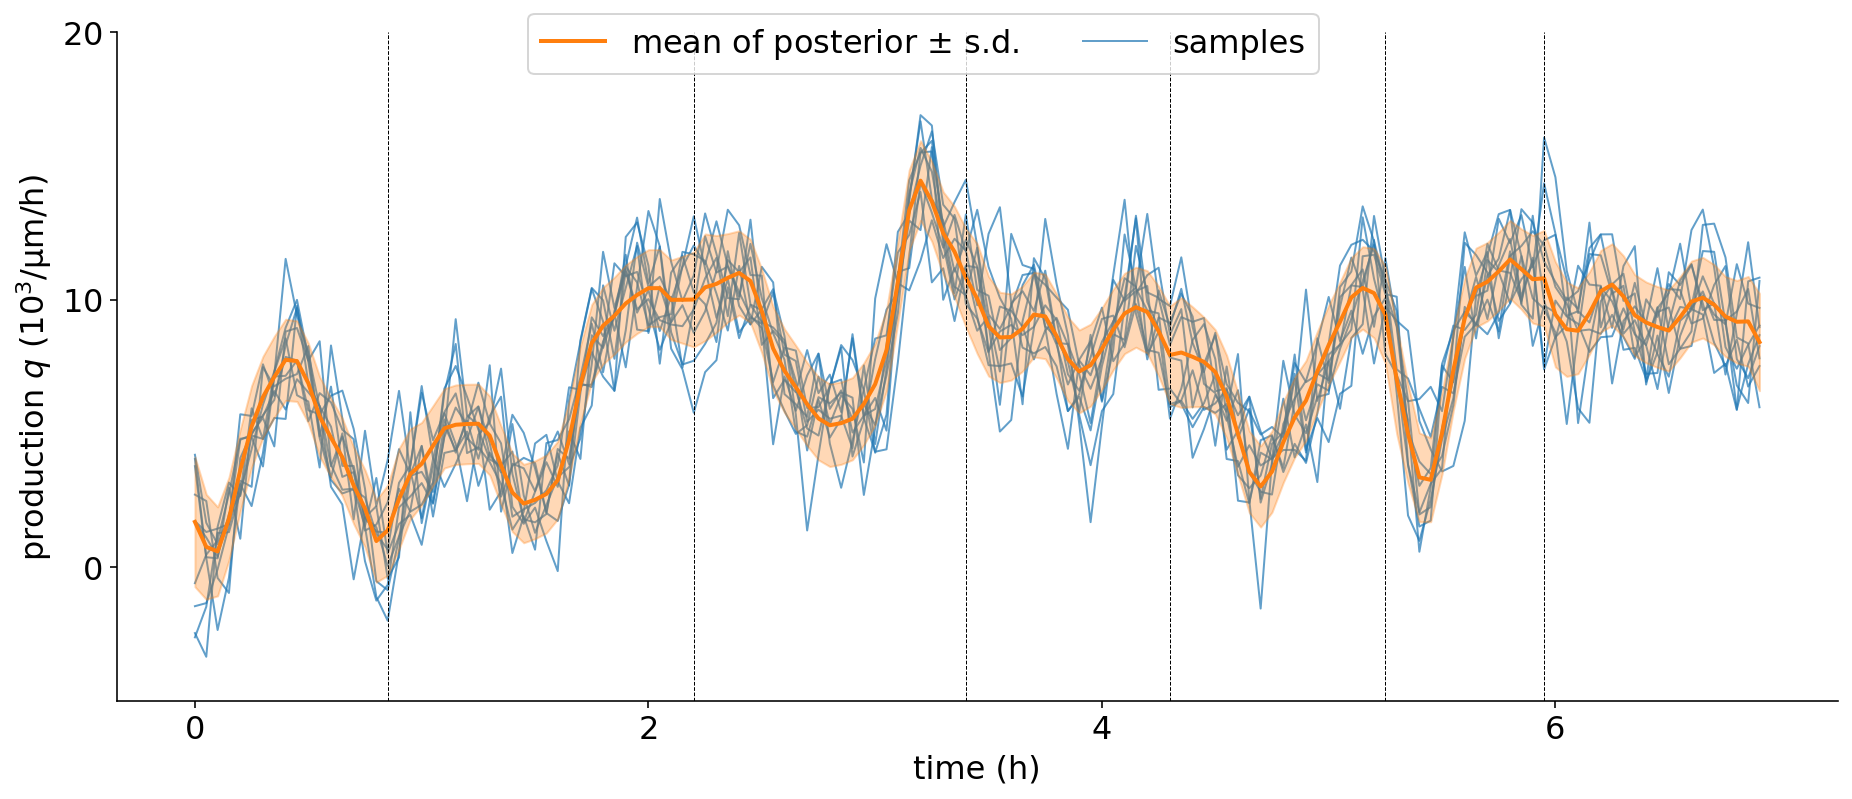

In [9]:
%load_ext autoreload
%autoreload 2



def plot_rate_residual(cells_true, cells_prediction, cells_noise, idx_cells, quantity, samples, cells_full=None,  
                title="", xlim=[None, None], ylim=[None, None], plot_file=None):
    # definitions for the axes

            
    fig, ax = plt.subplots(1, 1, figsize=(FULL_SIZE, FULL_HEIGHT*1.4))

    # ax.set_title("cell lineage for synthetic data")    
    for a in [ax]:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        # turn off the top spine/ticks
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        # remove first tick
        # a.xaxis.get_major_ticks()[0].set_visible(False)
        

    ###
    ax.set_xlabel("time (h)")
    ax.set_ylabel(title)

    label_cd = "cell division"
    label_p = "RealTrace"
    label_t = "true"
    label_n = "naive"

    prediction_coll = []
    noise_coll = []
    err_coll = []
    time_prediction_coll = []
    true_coll = []
    time_true_coll = []

    
    for i, _ in enumerate(cells_noise):
        if quantity == "lambda":
            prediction = np.array(cells_prediction[i].lt)
            err = np.sqrt(cells_prediction[i].cov_ll)
            true = np.array(cells_true[i].lt)
            
        elif quantity =="q":
            prediction = np.array(cells_prediction[i].qt)/1e3
            err = np.sqrt(cells_prediction[i].cov_qq)/1e3
            true = np.array(cells_true[i].qt)/1e3

             
        # prediction
        time_true_coll.append(cells_prediction[i].time)
        time_prediction_coll.append(cells_prediction[i].time)
        prediction_coll.append(prediction)
        err_coll.append(err)
        
        # truth
        true_coll.append(true)


    
    time_full_coll = []
    full_coll = []
    
    if cells_full!=None:
        for i, _ in enumerate(cells_full):
            if quantity == "lambda":
                full = np.array(cells_full[i].lt)
            elif quantity =="q":
                full = np.array(cells_full[i].qt)/1e3   

            time_full_coll.append(cells_full[i].time)
            full_coll.append(full)
            
    
    # Plots
    traces_time = index_nested(time_prediction_coll, idx_cells, True)
    time_shift= traces_time[0]
    
    ax.plot( (traces_time - time_shift)/60., 
             (index_nested(prediction_coll, idx_cells, True))*60, 
             color='tab:orange', alpha=1, zorder=2,lw=2, label="mean of posterior $\pm$ s.d.")

    ax.fill_between( (traces_time-time_shift)/60., 
                     (deep_flatten(index_nested(prediction_coll, idx_cells, True))-deep_flatten(index_nested(err_coll, idx_cells, True)))*60, 
                     (deep_flatten(index_nested(prediction_coll, idx_cells, True))+deep_flatten(index_nested(err_coll, idx_cells, True)))*60, 
                       color="tab:orange", alpha=0.3, zorder=2)

    label="samples"
    for i, sample in enumerate(samples):
        if quantity == "lambda":
            sample_coll = [np.array(cell.lt) for cell in sample]
        elif quantity =="q":
            sample_coll = [np.array(cell.qt)/1e3 for cell in sample]
            
        ax.plot( (traces_time - time_shift)/60., 
             (index_nested(sample_coll, idx_cells, True))*60, 
             color='tab:blue', zorder=-1,lw=1, alpha=0.7, label=label)
        label=None
            
    # ax.plot( (index_nested(time_full_coll, idx_cells, True)-time_shift)/60., 
    #          index_nested(full_coll, idx_cells, True)*60., 
    #          color='tab:green',  label=label_t, alpha=1, lw=1, zorder=1)

    
    # ax.plot( (index_nested(time_noise_coll, idx_cells, True)-time_shift)/60., 
    #          index_nested(noise_coll, idx_cells, True)*60., 
    #          color='tab:grey', lw=1, label=label_n, alpha=1, ls='-', zorder=1)

    
    # cell division
    for i in idx_cells[:-1]:
        ax.axvline( (cells_prediction[i].time[-1]-time_shift)/60.,color='black', ls='--', lw=0.5)
        label_cd = None

    if xlim!=[None,None]:
        ax.set_xlim(xlim)
    if ylim!=[None,None]:
        ax.set_ylim(ylim)
    ax.ticklabel_format(axis='y', style='scientific', scilimits=[-4,4], useMathText=True)

    fig.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5,1.))
        
   
    if quantity =="q":
        ax.xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=2))
        ax.yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=10))

    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')

    plt.show()



plot_rate_residual(cells_true, cells_prediction, cells_noise, get_longest_path(cells_noise)[:7], 
                   "q",  
                   samples,
                   cells_full=cells_full,
                   title=r"production $q$ ($\mathrm{10^3/\mu m/h}$)", 
                   xlim=[None, None], 
                   ylim = [-5, 20],
                   plot_file="../../figures_for_method_paper/supp/samples/lineage_q_samples.pdf")




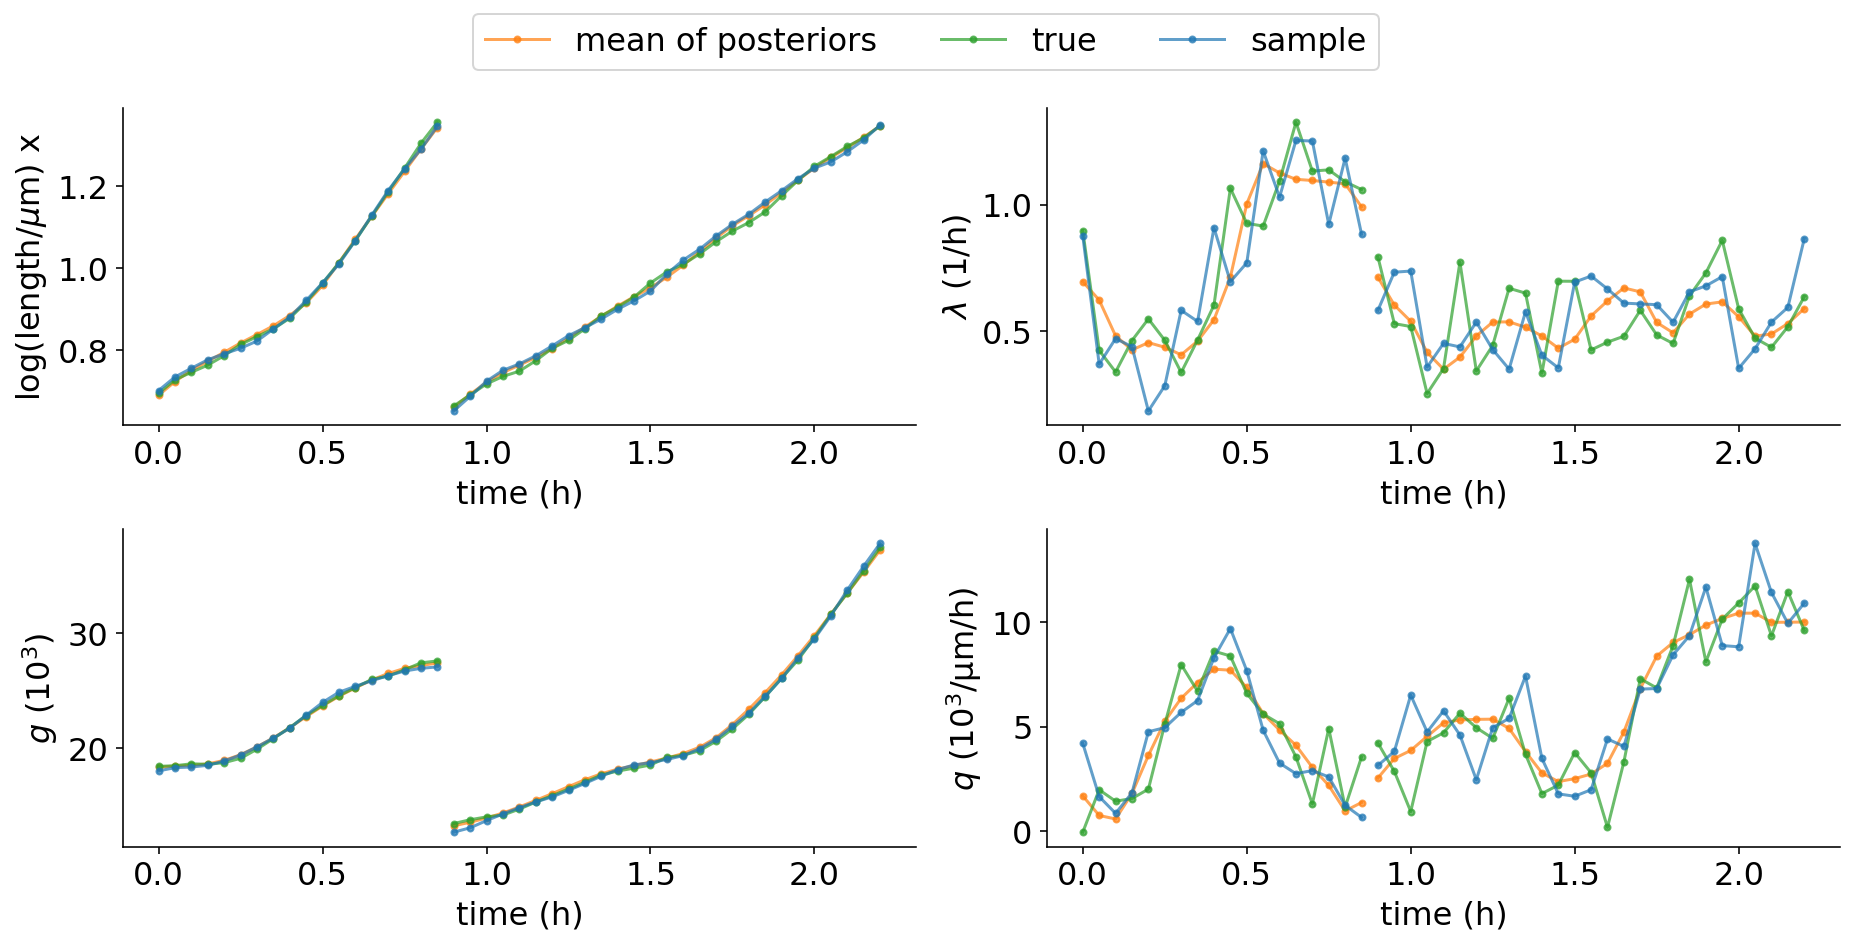

In [17]:

def plot_cell_state_sample(cells_true, cells_prediction,
                           idx_cells, samples, cells_full=None,  
                            title="", xlim=[None, None], ylim=[None, None], plot_file=None):

                
    fig, ax = plt.subplots(2, 2, figsize=(FULL_SIZE, FULL_HEIGHT*1.5))
    ax = ax.transpose().ravel()
    # ax.set_title("cell lineage for synthetic data")    
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        # turn off the right spine/ticks
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        # turn off the top spine/ticks
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()
        # remove first tick
        a.set_xlabel("time (h)")
        # a.xaxis.get_major_ticks()[0].set_visible(False)
    
    shift = cells_prediction[idx_cells[0]].time[0]/60
    
    label_p="mean of posteriors"
    label_t="true"
    label_s="sample"
    
    for i in idx_cells:
        cell_p = cells_prediction[i]
        cell_s = samples[0][i]
        cell_f = cells_true[i] 
        alpha = 0.7
        
        ax[0].plot(np.array(cell_p.time)/60.-shift,  cell_p.log_length, color="tab:orange", marker=".", alpha=alpha,label=label_p )
        ax[0].plot(np.array(cell_f.time)/60.-shift,  cell_f.log_length, color="tab:green", marker=".", alpha=alpha,label=label_t )
        ax[0].plot(np.array(cell_s.time)/60.-shift,  cell_s.log_length, color="tab:blue", marker=".", alpha=alpha,label=label_s)
        
        label_p=None
        label_t=None
        label_s=None
        
        ax[1].plot(np.array(cell_p.time)/60.-shift,  np.array(cell_p.gfp)/1e3, color="tab:orange",alpha=alpha, marker=".")
        ax[1].plot(np.array(cell_f.time)/60.-shift,  np.array(cell_f.gfp)/1e3, color="tab:green", alpha=alpha,marker=".")
        ax[1].plot(np.array(cell_s.time)/60.-shift,  np.array(cell_s.gfp)/1e3, color="tab:blue",alpha=alpha, marker=".")
        
        ax[2].plot(np.array(cell_p.time)/60.-shift,  np.array(cell_p.lt)*60, color="tab:orange",alpha=alpha, marker=".")
        ax[2].plot(np.array(cell_f.time)/60.-shift,  np.array(cell_f.lt)*60, color="tab:green", alpha=alpha,marker=".")
        ax[2].plot(np.array(cell_s.time)/60.-shift,  np.array(cell_s.lt)*60, color="tab:blue", alpha=alpha,marker=".")
    
        ax[3].plot(np.array(cell_p.time)/60.-shift,  np.array(cell_p.qt)/1e3*60, color="tab:orange",alpha=alpha, marker=".")
        ax[3].plot(np.array(cell_f.time)/60.-shift,  np.array(cell_f.qt)/1e3*60, color="tab:green",alpha=alpha, marker=".")
        ax[3].plot(np.array(cell_s.time)/60.-shift,  np.array(cell_s.qt)/1e3*60, color="tab:blue", alpha=alpha,marker=".")


    ax[0].set_ylabel("log(length/$\mu$m) x")  
    ax[1].set_ylabel("$g$ ($10^3$)")   
    ax[2].set_ylabel(r"$\lambda$ (1/h)")   
    ax[3].set_ylabel(r"$q$ $\mathrm{(10^3/\mu m/h)}$")   

    fig.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5,1.))

    
    plt.tight_layout()
    if plot_file!=None:
        plt.savefig(plot_file, bbox_inches='tight')

    plt.show()



plot_cell_state_sample(cells_true, 
                       cells_prediction, 
                       get_longest_path(cells_prediction)[:2], 
                       samples, cells_full,
                    plot_file="../../figures_for_method_paper/supp/samples/all_variables.pdf")
                      